# Exploración de estaciones y capacidad para P2 — MiBici

**Proyecto:** TC5061 · Equipo 52 · Pregunta P2 (clasificación)
**Autor:** Roberto Robles · **Rama:** `feature/p2-riesgo-estaciones`
**Antecedente:** `1.0-rr-p2-exploracion-datos.ipynb` (inventario de archivos y tendencias de viajes).

**Propósito.** Conocer las estaciones de MiBici y su capacidad (número de anclajes), dato que P2 necesita para aproximar el riesgo de quedarse sin bicicletas o sin anclajes.

**Debemos determinar:**
1. El número de estaciones en la nomenclatura y su número de anclajes (capacidad).
2. El número de estaciones que estuvieron activas en cada periodo.
3. El número de estaciones que aparecen en los viajes y tienen capacidad registrada en la nomenclatura, y cuáles no la tienen.

**Datos personales.** Solo se leen las columnas de estación de origen y de destino; no se leen las columnas de usuario, género ni año de nacimiento, para preservar la privacidad de la información.

In [1]:
# Objetivo: preparar el entorno del notebook.
# Carga las librerías y toma la ruta de los datos desde config.py.
# Resultado esperado: número de archivos de viajes y la ruta de la nomenclatura encontrados en data/raw.

%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # raíz del proyecto, para importar el módulo
from equipo52_module.config import RAW_DATA_DIR

archivos_viajes = sorted(RAW_DATA_DIR.glob("datos_abiertos_*.csv"))
ruta_nomenclatura = RAW_DATA_DIR / "nomenclatura_2026_09.csv"

print(f"Archivos de viajes: {len(archivos_viajes)}")
print(f"Nomenclatura: {ruta_nomenclatura.name} (existe: {ruta_nomenclatura.exists()})")

2026-10-14 10:12:32.915 | INFO     | equipo52_module.config:<module>:11 - PROJ_ROOT path is: /Users/Roberto/Proyectos/equipo52_proyecto_mibici


Archivos de viajes: 142
Nomenclatura: nomenclatura_2026_09.csv (existe: True)


In [2]:
# Objetivo: conocer la nomenclatura de estaciones: el número de estaciones, identificar si sus identificadores se repiten
# y cómo se distribuye su capacidad (número de anclajes).
# Resultado esperado: número de estaciones, valores faltantes, resumen estadístico de la capacidad
# y la lista de estaciones con capacidad 0.

nomenclatura = pd.read_csv(ruta_nomenclatura)

print(f"Estaciones en la nomenclatura: {len(nomenclatura)}")
print(f"¿Identificadores únicos?: {nomenclatura['id'].is_unique}")
print(f"Valores faltantes por columna: {nomenclatura.isna().sum().to_dict()}\n")

print("Capacidad (anclajes por estación):")
display(nomenclatura["dpcapacity"].describe().round(1).to_frame("capacidad"))

print("Estaciones con capacidad 0:")
nomenclatura[nomenclatura["dpcapacity"] == 0]

Estaciones en la nomenclatura: 484
¿Identificadores únicos?: True
Valores faltantes por columna: {'id': 0, 'name': 0, 'latitude': 0, 'longitude': 0, 'dpcapacity': 0}

Capacidad (anclajes por estación):


,capacidad
count,484.0
mean,16.9
std,4.1
min,0.0
25%,15.0
50%,15.0
75%,19.0
max,39.0


Estaciones con capacidad 0:


,id,name,latitude,longitude,dpcapacity
94,99,ex-(ZPN-009) C. Del Corral / C. Nicolás Bravo,20.685108,-103.333746,0
104,109,ex-(ZPN-019) C. Cabecera Mpal. Juan Manuel / C.,20.723221,-103.385583,0
111,116,ex-(ZPN-026) C. 16 Sep. / C. Fray A. de Segovia,20.686920,-103.334670,0
129,138,ex-(ZPN-044),20.697050,-103.363220,0


In [3]:
# Objetivo: leer de todos los archivos solo las columnas de estación de origen y de destino (posiciones 6 y 7).
# Se leen por posición porque en el notebook 1.0 se encontró que el nombre de una columna cambia entre archivos.
# Estas columnas solo contienen dígitos, así que la codificación de caracteres no las afecta; aun así se verifica abajo.
# El año y el mes se toman del nombre de cada archivo.
# Resultado esperado: total de registros leídos (el notebook 1.0 contó 39,078,840 líneas de datos) y confirmación
# de que todos los identificadores de estación son números.

REGISTROS_INVENTARIO_1_0 = 39_078_840  # total de líneas de datos contado en el notebook 1.0


def leer_estaciones_de_viajes(ruta):
    """Lee las columnas de estación de origen y destino de un archivo mensual, como texto."""
    estaciones = pd.read_csv(ruta, usecols=[6, 7], dtype="string", encoding="latin-1")
    estaciones.columns = ["origen_id", "destino_id"]
    anio, mes = ruta.stem.split("_")[2:4]
    return estaciones.assign(anio=int(anio), mes=int(mes[:2]))


viajes_estaciones = pd.concat(
    [leer_estaciones_de_viajes(ruta) for ruta in archivos_viajes], ignore_index=True
)

print(f"Registros leídos: {len(viajes_estaciones):,}")
print(f"¿Coincide con el inventario del notebook 1.0?: {len(viajes_estaciones) == REGISTROS_INVENTARIO_1_0}")
for columna in ["origen_id", "destino_id"]:
    solo_digitos = viajes_estaciones[columna].str.fullmatch(r"\d+").fillna(False)
    print(f"{columna}: {solo_digitos.sum():,} con solo dígitos; {(~solo_digitos).sum():,} con otro valor o vacíos")

viajes_estaciones[["origen_id", "destino_id"]] = viajes_estaciones[["origen_id", "destino_id"]].astype(int)

Registros leídos: 39,078,840
¿Coincide con el inventario del notebook 1.0?: True
origen_id: 39,078,840 con solo dígitos; 0 con otro valor o vacíos
destino_id: 39,078,840 con solo dígitos; 0 con otro valor o vacíos


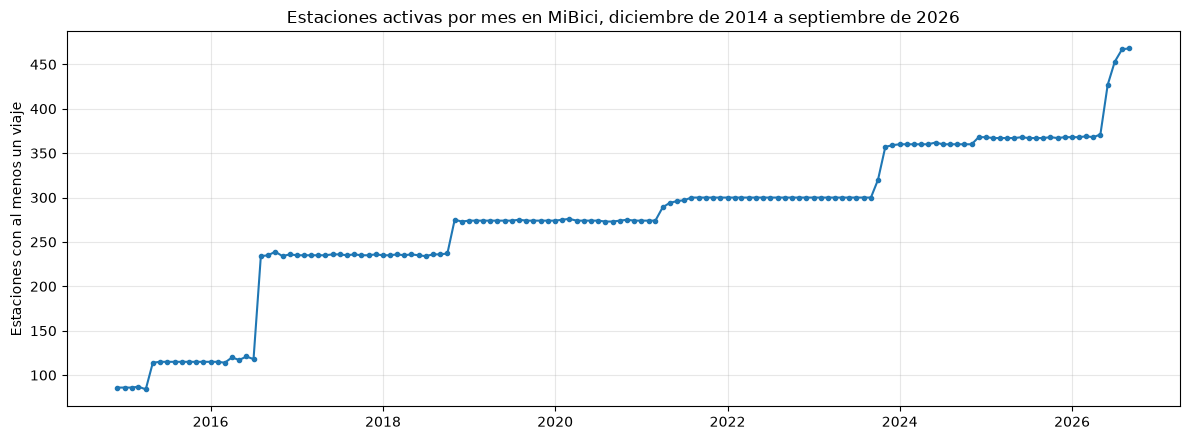

Estaciones activas por año (mínimo y máximo mensual):


,minimo,maximo
mes_inicio,,
2014,86,86
2015,84,115
2016,114,239
2017,235,236
2018,234,275
2019,274,275
2020,273,276
2021,274,300
2022,300,300


Estaciones activas en 2026:


,estaciones_activas
mes_inicio,
2026-01-01,368
2026-02-01,368
2026-03-01,369
2026-04-01,368
2026-05-01,371
2026-06-01,427
2026-07-01,453
2026-08-01,467
2026-09-01,468


In [4]:
# Objetivo: contar cuántas estaciones estuvieron activas cada mes. Una estación se considera activa en un mes
# si aparece como origen o destino de al menos un viaje.
# Resultado esperado: gráfica de estaciones activas por mes (guardada en reports/figures/), mínimo y máximo por año,
# y el detalle de 2026, que contiene el periodo de evaluación (abril a septiembre).

import matplotlib.pyplot as plt
from equipo52_module.config import FIGURES_DIR

estaciones_por_mes = (
    pd.concat([
        viajes_estaciones[["anio", "mes", "origen_id"]].rename(columns={"origen_id": "estacion_id"}),
        viajes_estaciones[["anio", "mes", "destino_id"]].rename(columns={"destino_id": "estacion_id"}),
    ])
    .drop_duplicates()
    .assign(mes_inicio=lambda datos: pd.to_datetime(dict(year=datos.anio, month=datos.mes, day=1)))
)
activas_por_mes = estaciones_por_mes.groupby("mes_inicio")["estacion_id"].nunique()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(activas_por_mes.index, activas_por_mes.values, marker="o", markersize=3)
ax.set_title("Estaciones activas por mes en MiBici, diciembre de 2014 a septiembre de 2026")
ax.set_ylabel("Estaciones con al menos un viaje")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "p2_estaciones_activas_por_mes.png", dpi=150)
plt.show()

print("Estaciones activas por año (mínimo y máximo mensual):")
display(activas_por_mes.groupby(activas_por_mes.index.year).agg(minimo="min", maximo="max"))

print("Estaciones activas en 2026:")
activas_por_mes.loc["2026-01":].to_frame("estaciones_activas")

In [5]:
# Objetivo: identificar cuándo aparecieron por primera vez las estaciones que empezaron a operar en 2026.
# Resultado esperado: número de estaciones nuevas según el mes de su primer viaje.

primer_mes_con_viajes = estaciones_por_mes.groupby("estacion_id")["mes_inicio"].min()
ultimo_mes_con_viajes = estaciones_por_mes.groupby("estacion_id")["mes_inicio"].max()

nuevas_2026 = primer_mes_con_viajes[primer_mes_con_viajes >= "2026-01-01"]
print(f"Estaciones con su primer viaje en 2026: {len(nuevas_2026)}")
nuevas_2026.dt.strftime("%Y-%m").value_counts().sort_index().to_frame("estaciones_nuevas")

Estaciones con su primer viaje en 2026: 100


,estaciones_nuevas
mes_inicio,
2026-05,12
2026-06,47
2026-07,27
2026-08,14


In [6]:
# Objetivo: comprobar si las estaciones cuyo nombre empieza con "ex-" dejaron de operar.
# Se compara con el último mes en que aparecen en los viajes.
# Resultado esperado: lista de estaciones "ex-" con su capacidad y el último mes con viajes.

estaciones_ex = nomenclatura[nomenclatura["name"].str.startswith("ex-")][["id", "name", "dpcapacity"]]
estaciones_ex.assign(
    ultimo_mes_con_viajes=estaciones_ex["id"].map(ultimo_mes_con_viajes).dt.strftime("%Y-%m")
)

,id,name,dpcapacity,ultimo_mes_con_viajes
19,22,ex-(GDL-020) Juan Manuel / C.General Coronado,15,2018-05
92,97,ex-(ZPN-007) C. Libertad / Nicolás Bravo,19,2017-06
94,99,ex-(ZPN-009) C. Del Corral / C. Nicolás Bravo,0,2016-10
104,109,ex-(ZPN-019) C. Cabecera Mpal. Juan Manuel / C.,0,2016-10
108,113,ex-(ZPN-023) C. Juan Diego / C. Sarcófago,11,2018-11
109,114,ex-(ZPN-024) Manuel H. Alatorre / C. Industria,11,2018-11
111,116,ex-(ZPN-026) C. 16 Sep. / C. Fray A. de Segovia,0,2016-10
129,138,ex-(ZPN-044),0,2016-10
138,147,ex-(TLQ-006) C. Zalatitán / Av. Francisco Silva,15,2017-07
140,149,ex-(TLQ-008) C. Juárez / C.Francisco de Miranda,15,2020-03


In [7]:
# Objetivo: verificar si todas las estaciones que aparecen en los viajes tienen capacidad registrada
# en la nomenclatura, y cuántos viajes se verían afectados si no la tienen.
# Resultado esperado: estaciones de los viajes que no están en la nomenclatura, con su número de viajes por año,
# y estaciones de la nomenclatura que nunca aparecen en los viajes.

ids_nomenclatura = set(nomenclatura["id"])
ids_en_viajes = set(estaciones_por_mes["estacion_id"])

sin_nomenclatura = sorted(ids_en_viajes - ids_nomenclatura)
print(f"Estaciones en los viajes: {len(ids_en_viajes)}")
print(f"Estaciones en los viajes que no están en la nomenclatura: {len(sin_nomenclatura)} → {sin_nomenclatura}")
print(f"Estaciones de la nomenclatura sin ningún viaje: {sorted(ids_nomenclatura - ids_en_viajes)}\n")

afectados = viajes_estaciones["origen_id"].isin(sin_nomenclatura) | viajes_estaciones["destino_id"].isin(sin_nomenclatura)
print(f"Viajes con origen o destino sin capacidad registrada: {afectados.sum():,} "
      f"({afectados.mean() * 100:.3f} % del total)")
viajes_estaciones[afectados].groupby("anio").size().to_frame("viajes_afectados")

Estaciones en los viajes: 486
Estaciones en los viajes que no están en la nomenclatura: 3 → [124, 405, 407]
Estaciones de la nomenclatura sin ningún viaje: [492]

Viajes con origen o destino sin capacidad registrada: 4,036 (0.010 % del total)


,viajes_afectados
anio,
2016,23
2017,24
2018,2
2019,26
2020,7
2026,3954


### Conclusiones de estaciones y capacidad

- **Nomenclatura (septiembre de 2026):** 484 estaciones con identificador único y sin valores faltantes. La capacidad va de 0 a 39 anclajes (promedio 16.9, mediana 15).
- **Estaciones dadas de baja:** 14 estaciones tienen nombre con el prefijo «ex-»; su último mes con viajes está entre octubre de 2016 y junio de 2025. Cuatro de ellas tienen capacidad 0.
- **Registros:** se leyeron 39,078,840 registros, la misma cifra del inventario del notebook 1.0; todos los identificadores de estación son numéricos.
- **Estaciones activas:** el número de estaciones con al menos un viaje al mes creció de 86 (diciembre de 2014) a 368 (enero a mayo de 2026, aproximadamente) y llegó a 468 en septiembre de 2026.
- **Expansión de 2026:** 100 estaciones tuvieron su primer viaje entre mayo y agosto de 2026 (12, 47, 27 y 14 por mes). Esta expansión coincide con septiembre de 2026, el mes con más viajes de la serie (notebook 1.0).
- **Cobertura de la capacidad:** de 486 estaciones que aparecen en los viajes, 3 (124, 405 y 407) no están en la nomenclatura; sus viajes son 4,036 (0.010 % del total), 3,954 de ellos en 2026. La estación 492 está en la nomenclatura pero no tiene viajes.

**Implicaciones para P2:**
1. Las 4 estaciones con capacidad 0 y las 3 sin capacidad registrada (124, 405 y 407) no pueden etiquetarse con riesgo. Se propone excluir también las 14 estaciones «ex-»: ninguna opera en el periodo de evaluación y su capacidad proviene de la nomenclatura de 2026, que podría no corresponder a cuando operaban. Las exclusiones se documentan.
2. La capacidad disponible es una sola fotografía (septiembre de 2026); no hay capacidad histórica.
3. El periodo de evaluación (abril a septiembre de 2026) incluye 100 estaciones con a lo sumo cuatro meses de historia, que el modelo no conocerá al entrenar. Propuesta para el equipo: calificar el modelo solo con las estaciones que ya operaban antes del periodo de evaluación y reportar por separado el desempeño en las estaciones nuevas. Esta decisión afecta también a P1 y P3.